# Guía L1 — La factura de la ciudad · **Sesión 2: la CHEC aterriza en Londres**

**Cálculo Diferencial — Laboratorio computacional** · Universidad Nacional de Colombia, Sede Manizales

> La sesión 1 nos dejó una nube de miles de consumos y un movimiento: condicionar hasta que la relación se vuelva función. Hoy la nube se llena de pesos colombianos, y el movimiento se repite con plata.

**Antes de empezar:** copia propia del cuaderno, la tarea puente lista (la verificación reproducida) y **el recibo de energía de su casa** sobre la mesa.

---
## ⏸️ Momento 1 — Predecir

P4 y P5 están en la guía. **En papel, a mano.** La apuesta de P5 —¿la nube (consumo, valor) con todos los estratos revueltos pasa el test de la recta vertical?— es la protagonista de hoy. Foto al informe antes de seguir.

---
## 1 · La tarifa en vivo: nuestra primera API

La sesión pasada el mesero nos trajo un plato congelado. Hoy pedimos en vivo: la URL de abajo es un **pedido** al portal de datos abiertos del Estado colombiano (`datos.gov.co`), y la respuesta es el pliego tarifario oficial de la CHEC — el mismo que decide cuánto paga su casa.

Detalle de la casa: las APIs sirven porciones. Sin el `$limit`, el mesero trae solo las primeras 1.000 filas y uno ni se entera. Leer la documentación del dataset **es** parte de leer el dataset.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RUTA_TARIFAS = "https://www.datos.gov.co/resource/c698-wqig.csv?$limit=60000"
# Si el wifi del laboratorio se cae, el monitor tiene la copia congelada (mismo formato):
# RUTA_TARIFAS = "https://raw.githubusercontent.com/cmorregof/labs-calculo-2026-2/main/datos/chec_tarifas_congeladas.csv"

tarifas = pd.read_csv(RUTA_TARIFAS)
print("Filas y columnas:", tarifas.shape)
print(list(tarifas.columns))

Filas y columnas: (40609, 24)
['costounitariotarifa_ano', 'costounitariotarifa_mes', 'comercializador_codigo', 'comercializador_nombre', 'mercado_codigo', 'mercado_nombre', 'costounitariotarifa_tipomed', 'nivel_tension_codigo', 'modalidadcobro_propiedad', 'claseservicio_codigo', 'claseservicio_descri', 'claseservicio_estrato', 'costounitariotarifa_rangoconsumo', 'costounitariotarifa_tipomercado', 'costounitariotarifa_generacion', 'costounitariotarifa_transmision', 'costounitariotarifa_distribucion', 'costounitariotarifa_comercializacion', 'costounitariotarifa_perdidas', 'costounitariotarifa_restricciones', 'costounitariotarifa_cu', 'costounitariotarifa_cureal', 'costounitariotarifa_subcon', 'costounitariotarifa_valor_tarifa']


In [ ]:
tarifas.head(10)   # las primeras 10 filas, para ver la cara de los datos

,costounitariotarifa_ano,costounitariotarifa_mes,comercializador_codigo,comercializador_nombre,mercado_codigo,mercado_nombre,costounitariotarifa_tipomed,nivel_tension_codigo,modalidadcobro_propiedad,claseservicio_codigo,...,costounitariotarifa_generacion,costounitariotarifa_transmision,costounitariotarifa_distribucion,costounitariotarifa_comercializacion,costounitariotarifa_perdidas,costounitariotarifa_restricciones,costounitariotarifa_cu,costounitariotarifa_cureal,costounitariotarifa_subcon,costounitariotarifa_valor_tarifa
0,2026,1,CHCC,CENTRAL HIDROELECTRICA DE CALDAS S.A. E.S.P.,1218,PEREIRA,HP,1,100% OR,ID,...,316.1193,56.8548,317.1201,24.7590,60.3769,36.6408,811.8709,0.0,0.2,974.2451
1,2026,8,CHCC,CENTRAL HIDROELECTRICA DE CALDAS S.A. E.S.P.,1218,PEREIRA,HP,1,50% OR,RS,...,407.1276,52.8111,293.6300,26.9370,70.7814,1.1262,852.4133,0.0,0.2,1022.8960
2,2026,8,CHCC,CENTRAL HIDROELECTRICA DE CALDAS S.A. E.S.P.,1234,CHEC,S,1,50% OR,RS,...,400.9351,49.3138,279.1654,122.7724,73.1938,6.0519,931.4324,0.0,0.0,931.4324
3,2026,8,CHCC,CENTRAL HIDROELECTRICA DE CALDAS S.A. E.S.P.,1218,PEREIRA,S,4,0% OR,CE,...,394.4369,49.3138,33.8498,26.9370,17.4178,6.0519,528.0072,0.0,0.0,528.0072
4,2026,8,CHCC,CENTRAL HIDROELECTRICA DE CALDAS S.A. E.S.P.,1234,CHEC,HM,1,0% OR,RS,...,388.4674,49.0045,242.3179,122.7724,71.2994,7.0686,880.9302,0.0,0.2,1057.1162
5,2026,8,CHCC,CENTRAL HIDROELECTRICA DE CALDAS S.A. E.S.P.,1218,PEREIRA,HP,1,0% OR,ID,...,407.1276,52.8111,271.2471,26.9370,70.7814,1.1262,830.0304,0.0,0.2,996.0365
6,2026,8,CHCC,CENTRAL HIDROELECTRICA DE CALDAS S.A. E.S.P.,1218,PEREIRA,S,1,50% OR,RS,...,394.4369,49.3138,293.6300,26.9370,68.5729,6.0519,838.9425,0.0,0.2,1006.7310
7,2026,8,CHCC,CENTRAL HIDROELECTRICA DE CALDAS S.A. E.S.P.,1234,CHEC,S,4,0% OR,RS,...,400.9351,49.3138,33.8498,122.7724,17.5921,6.0519,630.5151,0.0,0.0,630.5151
8,2026,9,CHCC,CENTRAL HIDROELECTRICA DE CALDAS S.A. E.S.P.,1234,CHEC,S,2,0% OR,RS,...,397.8180,43.8332,197.1035,122.6420,31.9758,6.9570,800.3295,0.0,0.0,800.3295
9,2026,8,CHCC,CENTRAL HIDROELECTRICA DE CALDAS S.A. E.S.P.,1218,PEREIRA,HM,1,100% OR,RS,...,381.2883,49.0045,316.0128,26.9370,66.6881,7.0686,846.9993,0.0,0.2,1016.3992


In [ ]:
print(max(tarifas["costounitariotarifa_valor_tarifa"]))

1336.8041


In [ ]:
# ✏️ Ejercicio 1 — El ritual, ahora sin acompañamiento: mirar antes de cruzar.
# Este dataset tiene más columnas y más trampas que el de Londres. Respondan con código:
#   a) ¿Qué mercados (mercado_nombre) aparecen y con cuántas filas cada uno?
#   b) ¿Qué años cubre el pliego? (ojo: la columna de año puede venir como texto "2,026")
#   c) ¿Qué estratos residenciales hay y qué valores toma el "rango de consumo"?
#   d) ¿Hay NaN donde no debería haberlos? ¿Y cuál es el DOMINIO de valor_tarifa?

# Normalizamos el año y el valor de una vez:
tarifas["ano"] = tarifas["costounitariotarifa_ano"].astype(str).str.replace(",", "").astype(int)
tarifas["valor"] = pd.to_numeric(tarifas["costounitariotarifa_valor_tarifa"], errors="coerce")

print(tarifas["mercado_nombre"].value_counts())
print("Años que cubre el pliego: ") # El priego cubre desde el año 2008 hasta el año 2026
print(tarifas["ano"].value_counts().sort_index())
print("Estratos residenciales: ") # Los estratos residenciales son 1,2,3,4,5,6
print(tarifas["claseservicio_estrato"].value_counts().sort_index())
print("Rango del consumo: ") # Los valores que toma el rango de consumo es 1 y 2
print(tarifas["costounitariotarifa_rangoconsumo"].value_counts())
print("Valores faltantes (NaN) por columna:") # Hay NaN en la columna de estratos; El dominio del valor_tarifa en el intervalo (0,1500) en los reales.
print(tarifas.isna().sum())


mercado_nombre
CHEC       37683
PEREIRA     2926
Name: count, dtype: int64

ano
2008    2251
2009    2509
2010    1417
2011    1824
2012    1934
2013    2004
2014    2046
2015    2124
2016    2124
2017    2124
2018    2125
2019    2136
2020    2151
2021    1996
2022    1848
2023    1848
2024    1848
2025    3465
2026    2835
Name: count, dtype: int64

claseservicio_estrato
1.0    2696
2.0    2832
3.0    2813
4.0    1140
5.0    2955
6.0    2907
Name: count, dtype: int64

costounitariotarifa_rangoconsumo
1    35389
2     5220
Name: count, dtype: int64
Valores faltantes (NaN) por columna:
costounitariotarifa_ano                     0
costounitariotarifa_mes                     0
comercializador_codigo                      0
comercializador_nombre                      0
mercado_codigo                              0
mercado_nombre                              0
costounitariotarifa_tipomed                 0
nivel_tension_codigo                        0
modalidadcobro_propiedad               

---
## 2 · La tarifa como función: `valor_factura`

Del pliego a la **función definida por trozos** que decide cuánto paga una casa. Dos ingredientes reales:

- El **consumo de subsistencia** (CS): en Manizales (2.150 m; la norma fija el umbral en 1.000 m de altitud) son **130 kWh/mes** (173 kWh/mes por debajo de los 1.000 m). Hasta ahí, los estratos 1–3 pagan tarifa subsidiada; de ahí en adelante, todos pagan tarifa plena. Búsquenlo en su recibo.
- El **pliego del mes**: lo sacamos del dataset, no de un número inventado. (El pliego trae variantes por propiedad de la red y nivel de tensión; tomamos las condiciones más comunes y la *mediana* cuando queda más de un valor — decisión de modelación, y queda escrita.)

Escriban la función en notación de la clase antes de leer el código: para estrato $e \le 3$,

$$V_e(x) = \begin{cases} t^{sub}_e \, x & 0 \le x \le CS \\ t^{sub}_e \, CS + t^{pl}\,(x - CS) & x > CS \end{cases}$$

¿Y para $e \ge 4$? ¿Es continua $V_e$ en $x = CS$? ¿Es derivable ahí? (Guarden la segunda pregunta: vuelve en el curso.)

In [ ]:
ANO_TARIFA, MES_TARIFA = 2026, 8   # el pliego que usaremos para cobrar (el más reciente)
CS = 130                            # kWh/mes de subsistencia para alturas >= 1000 m (Manizales: 2.150 m)

base = tarifas[(tarifas["mercado_nombre"] == "CHEC") &
               (tarifas["costounitariotarifa_tipomercado"] == "R") &
               (tarifas["nivel_tension_codigo"] == 1) &
               (tarifas["modalidadcobro_propiedad"] == "0% OR") &
               (tarifas["ano"] == ANO_TARIFA) &
               (pd.to_numeric(tarifas["costounitariotarifa_mes"]) == MES_TARIFA) &
               (tarifas["claseservicio_descri"].str.contains("Residencial Estrato", na=False))]

pliego = base.pivot_table(index="claseservicio_estrato",
                          columns="costounitariotarifa_rangoconsumo",
                          values="valor", aggfunc="median")
pliego.columns = ["subsidiada", "plena"][:len(pliego.columns)]
print("Pliego CHEC", ANO_TARIFA, "-", MES_TARIFA, "($/kWh):")
print(pliego.round(2))

def valor_factura(kwh, estrato):
    """Valor de la energía de un mes (sin cargo fijo, sin alumbrado): función por trozos."""
    t_sub = pliego.loc[estrato, "subsidiada"]
    t_plena = pliego.loc[estrato, "plena"] if not pd.isna(pliego.loc[estrato].get("plena", np.nan)) else t_sub
    if estrato <= 3:
        basico = min(kwh, CS) * t_sub       # el tramo subsidiado, hasta el CS
        resto  = max(kwh - CS, 0) * t_plena  # el resto, a tarifa plena
        return basico + resto
    else:
        return kwh * t_sub                   # estratos 4-6: un solo precio (4: pleno; 5-6: con contribución)

for kwh in [100, 130, 200, 300]:
    print(f"Estrato 3, {kwh} kWh → ${valor_factura(kwh, 3):,.0f}")

Pliego CHEC 2026 - 8 ($/kWh):
                       subsidiada   plena
claseservicio_estrato                    
1.0                        422.62  894.58
2.0                        528.28  894.58
3.0                        760.40  894.58
4.0                        894.58     NaN
5.0                       1073.50     NaN
6.0                       1073.50     NaN
Estrato 3, 100 kWh → $76,040
Estrato 3, 130 kWh → $98,852
Estrato 3, 200 kWh → $161,473
Estrato 3, 300 kWh → $250,931


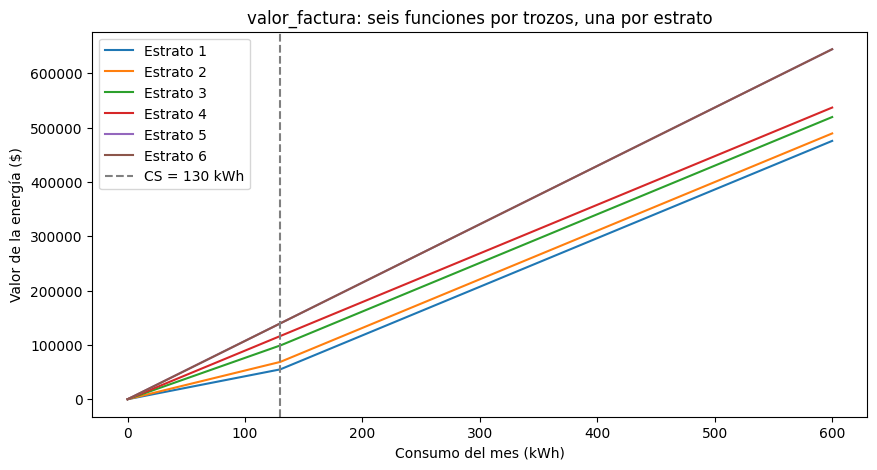

In [ ]:
# Seis curvas, una por estrato: la función por trozos, dibujada.
x = np.linspace(0, 600, 601)
plt.figure(figsize=(10, 5))
for e in range(1, 7):
    plt.plot(x, [valor_factura(k, e) for k in x], label=f"Estrato {e}")
plt.axvline(CS, linestyle="--", color="gray", label=f"CS = {CS} kWh")
plt.xlabel("Consumo del mes (kWh)"); plt.ylabel("Valor de la energía ($)")
plt.title("valor_factura: seis funciones por trozos, una por estrato")
plt.legend(); plt.show()

# 🗣️ ¿En qué estratos hay un 'codo' y en cuáles no? ¿Qué pasa con la pendiente antes y después del CS?

In [ ]:
# ✏️ Ejercicio 2 — La auditoría del recibo.
# Con el recibo de un integrante: consumo del mes (kWh), estrato, y valor pagado por ENERGÍA.
kwh_recibo   = 137     # ← su recibo
estrato_casa = 3      # ← su estrato
pago_real    = 124838      # ← lo que dice el recibo

print(f"El modelo dice: ${valor_factura(kwh_recibo, estrato_casa):,.0f}  |  El recibo dice: ${pago_real:,.0f}")

# El modelo se aproxima al valor real pero este no incluye cargos fijos como el valor del alumbrado publico,
# también el valor de la tarifa del modelo no concuerda con el de la factura

El modelo dice: $105,114  |  El recibo dice: $124,838


---
## 3 · La decisión de modelación: ¿qué estrato le toca a Londres?

Para cobrarle a un hogar londinense necesitamos asignarle un estrato — y eso es **supuesto nuestro**, no dato. Abajo hay un criterio de ejemplo (cuantiles de consumo, con proporciones parecidas a las de Manizales). Su equipo puede adoptarlo o cambiarlo, pero sea cual sea el criterio: **se defiende por escrito en tres líneas**. No hay criterio “correcto”; hay criterios defendibles y criterios que no se pensaron.

In [ ]:
# Cargamos Londres: la copia congelada de la sesión 1 (consumo MENSUAL por hogar).
RUTA = "https://raw.githubusercontent.com/cmorregof/labs-calculo-2026-2/main/datos/londres_mensual.csv"
df = pd.read_csv(RUTA)
print("Filas:", len(df), "| hogares:", df["hogar"].nunique())

# ✏️ Criterio de ejemplo (cámbienlo si quieren): el estrato se asigna POR HOGAR según su consumo
# mediano en todo el estudio (un hogar no cambia de estrato de un mes a otro).
consumo_hogar = df.groupby("hogar")["kwh"].median()
cortes = consumo_hogar.quantile([0, .25, .50, .70, .85, .95, 1.0]).values
estrato_hogar = pd.cut(consumo_hogar, bins=cortes, labels=[1, 2, 3, 4, 5, 6], include_lowest=True).astype(int)
df["estrato"] = df["hogar"].map(estrato_hogar)
print(estrato_hogar.value_counts().sort_index())

# 🗣️ Defensa del criterio (tres líneas, aquí): ¿por qué ESTE reparto y no otro?

Filas: 113440 | hogares: 5556
kwh
1    1389
2    1389
3    1111
4     833
5     556
6     278
Name: count, dtype: int64


---
## 4 · La nube: la ciudad facturada

Aplicamos `valor_factura` a los 113.440 pares (hogar, mes) y graficamos **(consumo, valor)**. Primero todos los estratos revueltos; relean P5 antes de correr la celda.

In [ ]:
df["valor"] = [valor_factura(k, e) for k, e in zip(df["kwh"], df["estrato"])]

muestra = df.sample(min(20000, len(df)), random_state=1)
plt.figure(figsize=(10, 5))
plt.scatter(muestra["kwh"], muestra["valor"], s=3, alpha=0.2, color="gray")
X0 = 250
plt.axvline(X0, color="red", linestyle="--", linewidth=1.5, label=f"Recta vertical en {X0} kWh")
plt.xlim(0, 1000); plt.ylim(0, valor_factura(1000, 6))
plt.xlabel("Consumo del mes (kWh)"); plt.ylabel("Valor de la energía ($)")
plt.title("Todos los estratos revueltos: ¿el valor es función del consumo?")
plt.legend(); plt.show()

cerca = df[(df["kwh"] > X0 - 1) & (df["kwh"] < X0 + 1)]
print(f"Hogares con consumo ≈ {X0} kWh: {len(cerca)} | valores distintos que pagan: {cerca['valor'].round(0).nunique()}")
print(cerca.groupby("estrato")["valor"].median().round(0))

🗣️ **La recta roja atraviesa la nube ¿en cuántos puntos?** Un mismo consumo, varios valores. Entonces, revueltos, el valor **no** es función solo del consumo: falta una variable en el dominio. ¿Cuál? Escríbanlo con la definición formal (dominio, codominio, regla) y confronten P5.

Ahora el movimiento de la sesión 1, con plata: **condicionar por estrato**.

In [ ]:
colores = {1: "#8c510a", 2: "#d8b365", 3: "#c9a227", 4: "#5aae61", 5: "#5ab4ac", 6: "#01665e"}
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for e in range(1, 7):
    sub = muestra[muestra["estrato"] == e]
    ax[0].scatter(sub["kwh"], sub["valor"], s=3, alpha=0.4, color=colores[e], label=f"Estrato {e}")
ax[0].set_xlim(0, 1000); ax[0].set_ylim(0, valor_factura(1000, 6))
ax[0].set_title("Coloreada por estrato: seis curvas limpias"); ax[0].legend(markerscale=3)
ax[0].set_xlabel("Consumo (kWh)"); ax[0].set_ylabel("Valor ($)")

# ✏️ Ejercicio 3 — Un solo estrato. Cambien E y comprueben con código que ahora sí es función:
E = 3
uno = df[df["estrato"] == E]
ax[1].scatter(uno["kwh"], uno["valor"], s=3, alpha=0.4, color=colores[E])
ax[1].axvline(X0, color="red", linestyle="--")
ax[1].set_title(f"Solo estrato {E}: una función por trozos")
ax[1].set_xlabel("Consumo (kWh)"); ax[1].set_ylabel("Valor ($)")
plt.tight_layout(); plt.show()

cerca_E = uno[(uno["kwh"] > X0 - 1) & (uno["kwh"] < X0 + 1)]
print(f"Estrato {E}, consumo ≈ {X0} kWh: {len(cerca_E)} hogares, ¿cuántos valores distintos? Miren:")
print(cerca_E[["kwh", "valor"]].head(8).round(1))
# 🗣️ Los valores casi coinciden pero no exactamente: ¿por qué? (Pista: 'consumo ≈ 250' no es 'consumo = 250'.)
#    ¿Qué tendrían que fijar para que la recta vertical atraviese EXACTAMENTE un punto?

🗣️ **Conclusión del movimiento, ahora con dinero:** al condicionar por estrato, la relación (consumo, valor) **se volvió** función, porque: *(dominio, codominio, regla)*. Y una pregunta para el informe: ¿cuál sería el dominio correcto de $V$ si quisiéramos que fuera función *sin* condicionar? (Pista: pares.)

---
## 5 · Cuantificar: el mismo aumento no cuesta lo mismo

Un hogar de estrato 3 aumenta su consumo en 25 kWh. ¿Cuánto más paga? Depende de **dónde** estaba.

In [ ]:
# ✏️ Ejercicio 4 — Dos aumentos iguales, dos cobros distintos.
for a, b in [(100, 125), (135, 160), (120, 145)]:
    delta = valor_factura(b, 3) - valor_factura(a, 3)
    print(f"Estrato 3, de {a} a {b} kWh (+{b-a} kWh): paga ${delta:,.0f} más  →  ${delta/(b-a):,.1f} por cada kWh adicional")

# 🗣️ ¿Por qué no es lo mismo, si el aumento de consumo fue igual? Expliquen con los tramos y con el CS.
#    El cociente 'pesos adicionales / kWh adicional' tiene nombre en este curso: ¿cuál? ¿Es constante en cada tramo?
#    ¿Qué pasa con ese cociente en el tercer intervalo, el que CRUZA el CS? ¿Es 'la pendiente' de algo?

# ✏️ Repitan para estrato 5: ¿cambia el cociente entre los dos intervalos? ¿Por qué?

In [ ]:
# La matriz de correlación: la covariación resumida en un número.
numericas = df[["kwh", "valor", "estrato"]]
print(numericas.corr().round(3))

# 🗣️ ¿Qué mide la correlación entre kwh y valor? ¿Por qué es alta pero NO es 1, si dentro de cada
#    estrato el valor es función del consumo? ¿Qué NO mide la correlación? (Pista: ¿detectaría una
#    relación en forma de U?) La correlación es la covariación — nuestro concepto rector — resumida
#    en un solo valor entre -1 y 1.

---
## 6 · El microdataset del curso

Cada estudiante sube **una fila** a la tabla compartida del curso: `(codigo_anonimo, mes, kwh, valor_pagado, estrato)` — su recibo, anonimizado.

🗣️ Discutan 10 minutos: ¿por qué la tabla tiene *esas* columnas y no otras? ¿Qué preguntas futuras permite responder esa estructura y cuáles cierra? Elegir la estructura de una tabla es decidir qué se va a poder preguntar — eso también es matemáticas.

In [ ]:
# La nube final: Londres facturado por la CHEC, con nosotros adentro.
plt.figure(figsize=(10, 5))
for e in range(1, 7):
    sub = muestra[muestra["estrato"] == e]
    plt.scatter(sub["kwh"], sub["valor"], s=3, alpha=0.3, color=colores[e], label=f"Estrato {e}")

# ✏️ Los puntos del curso (llenen con las filas del microdataset — kWh y valor por energía):
curso_kwh   = []   # p. ej. [180, 95, 210, ...]
curso_valor = []   # p. ej. [148000, 52000, 175000, ...]
plt.scatter(curso_kwh, curso_valor, s=90, marker="*", color="crimson", zorder=3, label="Nosotros")

plt.xlim(0, 1000); plt.ylim(0, valor_factura(1000, 6))
plt.xlabel("Consumo del mes (kWh)"); plt.ylabel("Valor de la energía ($)")
plt.title("Londres facturado por la CHEC — y nosotros, entre miles de hogares")
plt.legend(markerscale=3); plt.show()

# 🗣️ Ahí estamos, del otro lado del océano. ¿Nuestros puntos caen sobre la curva de su estrato? Si no, ¿por qué?

---
## 🗣️ Momento 3 — Explicar

Una página del equipo, aquí mismo: las dos discrepancias más interesantes entre predicción y resultado (P4, P5); la defensa del criterio de estratificación; y una reflexión de tres líneas sobre **qué fue real y qué fue supuesto** en todo lo que hicieron.

---
## 🤖 Protocolo de IA (recordatorio)

Las tres reglas del curso, siempre: intento propio antes de consultar; la IA no es la autoridad final; todo uso va a la bitácora individual. La **cacería puntuable** está en la guía: pídanle a una IA una función de Python que calcule la factura de energía con tarifas colombianas, *sin* darle el pliego, y audítenla contra la suya: ¿inventó valores? ¿cobró dos veces el tramo básico? ¿ignoró el estrato? ¿acertó el consumo de subsistencia de Manizales? Documenten el veredicto.

**Prohibido:** pedirle el criterio de estratificación, las conclusiones de los momentos 3, o el informe. Todo integrante debe poder explicar cualquier celda si el monitor la señala.

**Entregables** (cierre de esta semana): cuaderno `L1_apellidos.ipynb` ejecutado de arriba a abajo sin errores, con las predicciones fotografiadas y los tres momentos de ambas sesiones; bitácora de IA individual; la fila de cada estudiante en el microdataset; la tarea puente.